# LangGraph Basics: Building a Chatbot with Groq

**What you'll learn, step by step:**
1. Setup: load the Groq API key
2. **Messages**: the building blocks of every chat
3. Calling the LLM directly (no graph yet)
4. LangGraph core ideas: **State → Nodes → Edges**
5. A tiny graph *without* an LLM (to see how state flows)
6. A **chatbot graph** with the LLM
7. Adding **memory** so the bot remembers the conversation
8. An **interactive chat loop**
9. Streaming responses

> Run cells top to bottom with `Shift + Enter`.

## 1. Setup

Put your key in the `.env` file in this folder:
```
GROQ_API_KEY=gsk_...
```

In [1]:
import os
from dotenv import load_dotenv

load_dotenv()  # reads .env into environment variables

assert os.getenv("GROQ_API_KEY"), "GROQ_API_KEY not found. Add it to your .env file."
print("API key loaded ✅")

API key loaded ✅


## 2. Messages

A chat is just a **list of messages**. Each message has a *role* and *content*:

| Class | Role | Who writes it |
|---|---|---|
| `SystemMessage` | system | You: instructions/personality for the bot |
| `HumanMessage` | user | The user |
| `AIMessage` | assistant | The model |
| `ToolMessage` | tool | A tool's result (used later with tools) |

In [2]:
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage

messages = [
    SystemMessage(content="You are a helpful assistant who answers briefly."),
    HumanMessage(content="Hi! My name is Ali."),
    AIMessage(content="Hello Ali! How can I help you today?"),
    HumanMessage(content="What is my name?"),
]

for m in messages:
    m.pretty_print()

================================ System Message ================================

You are a helpful assistant who answers briefly.
================================ Human Message =================================

Hi! My name is Ali.
================================== Ai Message ==================================

Hello Ali! How can I help you today?
================================ Human Message =================================

What is my name?


## 3. Calling the LLM directly

`ChatGroq` is a LangChain chat model. You pass it a list of messages and it returns an `AIMessage`.

Some Groq models: `openai/gpt-oss-120b`, `openai/gpt-oss-20b` (faster/cheaper). Check the Groq console for the current list.

In [3]:
from langchain_groq import ChatGroq

llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0.7)

response = llm.invoke(messages)
print(type(response))
response.pretty_print()

<class 'langchain_core.messages.ai.AIMessage'>
================================== Ai Message ==================================

Your name is Ali.


In [4]:
# The response is an AIMessage; it has content plus metadata (token usage, etc.)
print("Content:", response.content)
print("Usage:  ", response.usage_metadata)

Content: Your name is Ali.
Usage:   {'input_tokens': 115, 'output_tokens': 47, 'total_tokens': 162, 'output_token_details': {'reasoning': 33}}


**Notice:** the model knew the name "Ali" only because we sent the *whole* history.
LLMs are **stateless**: memory = resending past messages. LangGraph helps manage this for us.

## 4. LangGraph core ideas

| Concept | What it is |
|---|---|
| **State** | A dict (`TypedDict`) shared by the whole graph. Every node reads it and returns updates. |
| **Node** | A plain Python function: `def node(state) -> dict_of_updates` |
| **Edge** | Says which node runs next. `START` and `END` are special nodes. |
| **Reducer** | Decides *how* an update is merged into state (overwrite vs. append). |

```
START ──► node_a ──► node_b ──► END
```

## 5. A tiny graph without an LLM

Just to see how state flows through nodes.

In [5]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END


class SimpleState(TypedDict):
    text: str
    steps: int


def make_upper(state: SimpleState):
    return {"text": state["text"].upper(), "steps": state["steps"] + 1}


def add_excitement(state: SimpleState):
    return {"text": state["text"] + "!!!", "steps": state["steps"] + 1}


builder = StateGraph(SimpleState)
builder.add_node("make_upper", make_upper)
builder.add_node("add_excitement", add_excitement)

builder.add_edge(START, "make_upper")
builder.add_edge("make_upper", "add_excitement")
builder.add_edge("add_excitement", END)

simple_graph = builder.compile()

simple_graph.invoke({"text": "hello langgraph", "steps": 0})

{'text': 'HELLO LANGGRAPH!!!', 'steps': 2}

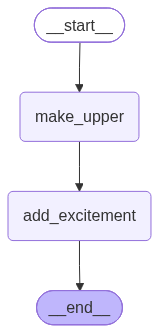

In [6]:
# Visualize the graph (renders as an image in Jupyter)
from IPython.display import Image, display

display(Image(simple_graph.get_graph().draw_mermaid_png()))

## 6. Chatbot graph

For chat, the state holds a list of `messages`. We use the `add_messages` **reducer** so new
messages are **appended** instead of overwriting the list.

```python
messages: Annotated[list, add_messages]
```

(LangGraph also ships a ready-made `MessagesState` that is exactly this.)

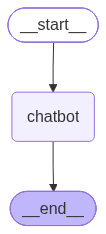

In [7]:
from typing import Annotated
from langgraph.graph.message import add_messages


class ChatState(TypedDict):
    messages: Annotated[list, add_messages]


SYSTEM_PROMPT = SystemMessage(content="You are a friendly assistant. Keep answers short.")


def chatbot(state: ChatState):
    # Send system prompt + full conversation to the LLM
    reply = llm.invoke([SYSTEM_PROMPT] + state["messages"])
    # Return only the NEW message; add_messages appends it to the list
    return {"messages": [reply]}


builder = StateGraph(ChatState)
builder.add_node("chatbot", chatbot)
builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", END)

chat_graph = builder.compile()

display(Image(chat_graph.get_graph().draw_mermaid_png()))

In [8]:
result = chat_graph.invoke({"messages": [HumanMessage(content="Hi, I'm Ali. Tell me a fun fact.")]})

for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hi, I'm Ali. Tell me a fun fact.
================================== Ai Message ==================================

Nice to meet you, Ali! 🌟 Fun fact: Octopuses have three hearts—two pump blood to the gills, and one pumps it to the rest of the body.


In [9]:
# Problem: a new invoke starts with an empty state, so the bot forgets
result = chat_graph.invoke({"messages": [HumanMessage(content="What is my name?")]})
result["messages"][-1].pretty_print()

================================== Ai Message ==================================

I’m not sure—could you remind me of your name?


## 7. Adding memory (checkpointer)

A **checkpointer** saves the state after every run. Each conversation gets a `thread_id`.
Same `thread_id` → the bot remembers. New `thread_id` → fresh conversation.

`InMemorySaver` keeps it in RAM (lost on kernel restart). For persistence you'd use SQLite/Postgres savers later.

In [10]:
from langgraph.checkpoint.memory import InMemorySaver

memory = InMemorySaver()
chat_graph = builder.compile(checkpointer=memory)

config = {"configurable": {"thread_id": "conversation-1"}}

chat_graph.invoke({"messages": [HumanMessage(content="Hi, my name is Ali.")]}, config)
result = chat_graph.invoke({"messages": [HumanMessage(content="What is my name?")]}, config)
result["messages"][-1].pretty_print()

================================== Ai Message ==================================

Your name is Ali.


In [11]:
# A different thread = a different conversation
other = {"configurable": {"thread_id": "conversation-2"}}
result = chat_graph.invoke({"messages": [HumanMessage(content="What is my name?")]}, other)
result["messages"][-1].pretty_print()

================================== Ai Message ==================================

I’m not sure—I don’t have your name. Could you tell me?


In [12]:
# Inspect what's stored for a thread
snapshot = chat_graph.get_state(config)
print(f"{len(snapshot.values['messages'])} messages in thread 'conversation-1'")
for m in snapshot.values["messages"]:
    print(f"{m.type:>6}: {m.content[:80]}")

4 messages in thread 'conversation-1'
 human: Hi, my name is Ali.
    ai: Hi Ali! Nice to meet you. How can I help you today?
 human: What is my name?
    ai: Your name is Ali.


## 8. Interactive chat loop

Type messages in the input box below the cell. Type `quit` / `exit` / `q` to stop.

In [ ]:
def chat(thread_id: str = "interactive-1"):
    config = {"configurable": {"thread_id": thread_id}}
    print("Chat started. Type 'quit' to stop.\n")
    while True:
        user_input = input("You: ")
        if user_input.strip().lower() in {"quit", "exit", "q"}:
            print("Goodbye! 👋")
            break
        result = chat_graph.invoke({"messages": [HumanMessage(content=user_input)]}, config)
        print("Bot:", result["messages"][-1].content, "\n")


chat()

Chat started. Type 'quit' to stop.



You:  Hey, how are you?


Bot: I'm good, thanks! How can I help you today? 



You:  Whats algebra?


Bot: Algebra is a branch of math that uses symbols (like x, y) to represent numbers and express relationships. It lets you write general formulas, solve equations, and work with unknown quantities. In short, it’s the language for describing and solving patterns and problems using variables. 



You:  Whats the most reliable parameter numbers for a LLM model to Answer Accurately?


Bot: The “sweet spot” depends on what you need, but a few rule‑of‑thumbs are:

| Model size | Typical use‑case | Accuracy vs. cost |
|------------|------------------|-------------------|
| **< 1 B params** | Simple chatbots, on‑device inference | Fast & cheap, but limited reasoning |
| **1 – 7 B params** | General‑purpose assistants, small‑scale research | Good fluency; decent factual recall; still lightweight |
| **7 – 30 B params** | More demanding QA, code generation, nuanced dialogue | Noticeable jump in factual accuracy and reasoning; requires a GPU/TPU server |
| **30 – 100 B params** | State‑of‑the‑art chat, complex problem solving | Near‑human‑level performance on many benchmarks; high compute & memory cost |
| **> 100 B params** (e.g., 175 B GPT‑3, 540 B PaLM) | Cutting‑edge research, enterprise‑grade APIs | Best overall accuracy across diverse tasks; very expensive to train/run |

**Why bigger isn’t always “best”:**  
- **Data quality** matters more than raw size. A 7 B model

## 9. Streaming

Instead of waiting for the full answer, print tokens as they arrive with `stream_mode="messages"`.

In [ ]:
config = {"configurable": {"thread_id": "stream-demo"}}

for chunk, metadata in chat_graph.stream(
    {"messages": [HumanMessage(content="Explain LangGraph in 3 short bullet points.")]},
    config,
    stream_mode="messages",
):
    print(chunk.content, end="", flush=True)

## Recap

- **Messages** = the conversation (`SystemMessage`, `HumanMessage`, `AIMessage`)
- **State** = shared data; `add_messages` appends instead of overwriting
- **Node** = function that takes state and returns updates
- **Edges** = control flow (`START → chatbot → END`)
- **Checkpointer + thread_id** = memory across turns

### Try it yourself
1. Change the `SYSTEM_PROMPT` to give the bot a personality (pirate, teacher, ...).
2. Switch the model to `openai/gpt-oss-20b` and compare speed.
3. Add a second node that counts how many turns happened (add a `turns: int` field to the state).
4. **Next topic:** tools + conditional edges (`ToolNode`, `tools_condition`) to build an agent.